# Dataset Understanding and EDA
**Unit 3 · Lesson 3 | PV Time Series**

Continue from **Lesson 2: Data Preparation Workflow**. Read its saved **training partition**, understand the observations, investigate data quality and relationships, and document evidence for later preprocessing.

**Workflow:** Prepared chronological partitions → Training-only EDA → Findings and next-step decisions.

**Learning outcomes**
- Distinguish storage types, semantic feature types, identifiers, and future targets.
- Inspect distributions, cardinality, missingness, duplicates, temporal continuity, and relationships.
- Flag suspicious observations with domain checks, box plots, IQR, and z-scores.
- Summarize EDA findings in this notebook without changing the prepared data.

The slides introduce image classification and two time-series scenarios. This notebook continues the **same PV time-series dataset** used in Lesson 2; image-specific examples are not applied to this table.

## Setup
Run Lesson 2 first. This notebook does **not** reopen the raw Excel file, rename columns again, rebuild targets, or repeat the split.

```text
project_root/
├── data/
│   ├── raw/PV_Data.xlsx
│   └── processed/pv_time_series/
│       ├── pv_time_series_train.csv
│       ├── pv_time_series_validation.csv
│       ├── pv_time_series_test.csv
│       └── column_mapping.csv
└── chapter_03/
    ├── 03_02_data_preparation_workflow_pv_time_series.ipynb
    └── 03_03_dataset_understanding_and_eda_pv_time_series.ipynb
```

Data stays outside chapter folders for reuse. Tables, plots, and interpretation stay in this notebook; no separate report files are needed.

**Local:** Start from the chapter folder; adjust `PROJECT_ROOT` if your working directory differs.

**Colab:** Uncomment the runtime path below if Lesson 2 exports are already in `/content/pv_course`. For a new runtime, use the optional Drive cell to read the saved training CSV. Colab runtime storage is temporary. Keep the Lesson 2 CSVs in persistent storage such as Drive, and save a copy of this notebook to retain your work. Saving the notebook does not back up runtime data files.

Installations and optional imports are collected here and commented out. `gdown` is needed only for the optional file-ID download.

In [1]:
# %pip install pandas numpy matplotlib
# %pip install gdown

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import gdown
# from google.colab import drive

### Project paths

In [3]:
# PROJECT_ROOT = Path("..").resolve()
PROJECT_ROOT = Path("/content")

DATA_DIR = PROJECT_ROOT / "data/processed/pv_time_series"
TRAIN_PATH = DATA_DIR / "pv_time_series_train.csv"

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True})

### Optional: Read the Lesson 2 training partition from Drive
Uncomment the `drive` import and this cell in Colab. Replace the example path if necessary. Only the input path changes; all analysis is displayed in this notebook. Mounting Drive does not copy the validation or test partitions into memory.

In [4]:
# drive.mount("/content/drive")
# TRAIN_PATH = Path(
#     "/content/drive/MyDrive/pv_course/data/processed/pv_time_series/"
#     "pv_time_series_train.csv"
# )

### Optional alternative: Download the training CSV with gdown
Use **either** the Drive-path option above **or** this file-ID option. Uncomment the `gdown` installation and import in Setup, then this cell.

The ID must refer to **`pv_time_series_train.csv` exported by Lesson 2**, not the raw workbook or full dataset. The file must be accessible through its sharing link; for private data, prefer mounted Drive. Copy the ID from `https://drive.google.com/file/d/FILE_ID/view`.

The download goes to the shared project data folder and overwrites that local filename. Colab runtime storage is temporary; keep the original CSV on Drive.

In [5]:
file_id = "YOUR_TRAINING_CSV_FILE_ID"
TRAIN_PATH = DATA_DIR / "pv_time_series_train.csv"
TRAIN_PATH.parent.mkdir(parents=True, exist_ok=True)
gdown.download(id=file_id, output=str(TRAIN_PATH), quiet=False)

Downloading...
From: https://drive.google.com/uc?id=1nZuDEW1IYjKRMpuvPLDROXXDKaX3ip3R
To: /content/data/processed/pv_time_series/pv_time_series_train.csv
100%|██████████| 623k/623k [00:00<00:00, 68.6MB/s]


'/content/data/processed/pv_time_series/pv_time_series_train.csv'

## 1. Scope and Leakage Control
| Item | Meaning in this notebook |
|---|---|
| Dataset | Prepared PV-system observations from Lesson 2 |
| Row | One recorded hourly interval, not yet a supervised learning sample |
| Prediction origin | End of interval t, assuming measurements are available then |
| Future regression target | Total PV output at t+1 |
| Future classification target | Low, Medium, or High output at t+1 |
| EDA population | Training observations only |

**Keep validation and test isolated.** Do not use their distributions, outliers, or statistics to choose preprocessing rules. This notebook does not even load those files.

`total_pv_power` is an observed value at **t**, not an aligned target at **t+1**. We inspect its distribution but do not call it the future-target distribution. Target alignment, class thresholds, and class-balance analysis are deferred until samples are constructed. The next row is only the next hour when temporal continuity holds.

No imputation, scaling, encoding, automatic outlier removal, feature selection, resampling, shuffling, or model training is performed.

**EDA only:** All summaries, flags, and plotting coordinates are separate analysis objects. No feature, target, flag, or time column is added to `train_data`, and no revised dataset is exported.

## 2. Load and Inspect the Training Partition
### 2.1 Read first, transform later
The CSV already has standardized headers and contains no saved index column. `read_csv` recognizes standard missing-value tokens; a separate text-only audit later checks other markers without modifying this DataFrame.

In [6]:
if not TRAIN_PATH.is_file():
    raise FileNotFoundError(
        f"Training dataset not found at: {TRAIN_PATH}\n"
        "Generate the training CSV using the Lesson 2 notebook, "
        "or update TRAIN_PATH to the location of the existing file."
    )

train_data = pd.read_csv(TRAIN_PATH)
print("Rows and columns:", train_data.shape)

Rows and columns: (4956, 21)


### Inspect the first and last observations

In [7]:
display(train_data.head())
display(train_data.tail())

,day,cosine_of_day,hour,cosine_of_hour,air_temperature,dewpoint,wind_speed,air_pressure,weather_condition,solar_radiation,...,pv_1_power,pv_2_cosine_value_of_the_solar_incidence_angle,pv_2_power,pv_3_cosine_value_of_the_solar_incidence_angle,pv_3_power,pv_4_cosine_value_of_the_solar_incidence_angle,pv_4_power,pv_5_cosine_value_of_the_solar_incidence_angle,pv_5_power,total_pv_power
0,1,0.999852,1,1.0000,2,81,6,900.2,10,0.0,...,0,0.0,0,0.0,0,0.0,0,0.0,0,0
1,1,0.999852,2,0.9659,-1,86,0,900.2,10,0.0,...,0,0.0,0,0.0,0,0.0,0,0.0,0,0
2,1,0.999852,3,0.8660,0,87,6,900.2,10,0.0,...,0,0.0,0,0.0,0,0.0,0,0.0,0,0
3,1,0.999852,4,0.7071,-1,86,2,900.2,10,0.0,...,0,0.0,0,0.0,0,0.0,0,0.0,0,0
4,1,0.999852,5,0.5000,-1,86,6,900.2,10,0.0,...,0,0.0,0,0.0,0,0.0,0,0.0,0,0


,day,cosine_of_day,hour,cosine_of_hour,air_temperature,dewpoint,wind_speed,air_pressure,weather_condition,solar_radiation,...,pv_1_power,pv_2_cosine_value_of_the_solar_incidence_angle,pv_2_power,pv_3_cosine_value_of_the_solar_incidence_angle,pv_3_power,pv_4_cosine_value_of_the_solar_incidence_angle,pv_4_power,pv_5_cosine_value_of_the_solar_incidence_angle,pv_5_power,total_pv_power
4951,207,-0.912375,8,-0.2588,21,53,28,898.5,10,256.0,...,30,0.240784,30,0.315166,24,0.368071,23,0.395891,23,130
4952,207,-0.912375,9,-0.5000,22,50,26,898.5,10,432.0,...,86,0.435763,81,0.527925,45,0.584110,60,0.600490,63,335
4953,207,-0.912375,10,-0.7071,24,44,22,898.5,10,657.0,...,149,0.592820,136,0.702155,159,0.763638,172,0.773081,176,792
4954,207,-0.912375,11,-0.8660,26,36,17,899.4,10,804.0,...,187,0.701253,170,0.825981,197,0.894419,206,0.901905,208,968
4955,207,-0.912375,12,-0.9659,26,34,19,899.4,10,902.0,...,221,0.753671,194,0.890965,226,0.967541,235,0.978181,235,1111


### 2.2 Structure and schema
Check the first and last time labels, column names, storage types, and non-null counts. A numeric storage type does not imply a continuous feature: `weather_condition` is a category code.

The original workbook describes output units as **“W or Wh.”** Do not label plots as kW, infer installed capacity, or convert power to energy without source confirmation. Verify units and definitions for weather measurements too; a column name alone is not sufficient evidence.

In [8]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4956 entries, 0 to 4955
Data columns (total 21 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   day                                             4956 non-null   int64  
 1   cosine_of_day                                   4956 non-null   float64
 2   hour                                            4956 non-null   int64  
 3   cosine_of_hour                                  4956 non-null   float64
 4   air_temperature                                 4956 non-null   int64  
 5   dewpoint                                        4956 non-null   int64  
 6   wind_speed                                      4956 non-null   int64  
 7   air_pressure                                    4956 non-null   float64
 8   weather_condition                               4956 non-null   int64  
 9   solar_radiation                          

### Schema summary

In [9]:
schema = pd.DataFrame({
    "dtype": train_data.dtypes.astype(str),
    "non_null_count": train_data.notna().sum(),
    "unique_non_null": train_data.nunique(dropna=True),
})
display(schema)

,dtype,non_null_count,unique_non_null
day,int64,4956,207
cosine_of_day,float64,4956,191
hour,int64,4956,24
cosine_of_hour,float64,4956,13
air_temperature,int64,4956,51
dewpoint,int64,4956,83
wind_speed,int64,4956,28
air_pressure,float64,4956,36
weather_condition,int64,4956,9
solar_radiation,float64,4956,868


## 3. Column Meaning, Feature Types, and Identifiers
### 3.1 Semantic roles
These roles come from the source documentation, not automatic inference. They do not define the final model inputs.

| Column(s) | Semantic type | Role / interpretation |
|---|---|---|
| `day`, `hour` | Temporal / discrete | Interval labels; jointly identify time under the single-year assumption |
| `weather_condition` | Categorical / nominal | Weather code; verify the codebook before interpreting or encoding |
| `pv_1_power`–`pv_5_power` | Numerical | Observed output of individual PV units |
| `total_pv_power` | Numerical | Observed total output at the current interval; source for a future target |
| Cosine columns | Numerical | Existing descriptors; confirm their definitions in the documentation |
| `air_temperature`, `dewpoint`, `wind_speed`, `air_pressure`, `solar_radiation` | Numerical | Weather measurements; verify definitions and units |

Numeric storage does not imply a continuous measurement. No future target or ordinal class has been constructed in this lesson.

### 3.2 Cardinality and category frequencies
`nunique()` counts distinct values; `unique()` shows which values occur; `value_counts()` shows their frequency. High cardinality can mean an identifier **or** a legitimate continuous measurement. Low cardinality does not by itself imply a category.

Weather-code frequencies below are **feature frequencies**, not target-class balance. No weather-code ordering or class labels are inferred.

In [10]:
cardinality = pd.DataFrame({
    "unique_non_null": train_data.nunique(dropna=True),
    "missing_count": train_data.isna().sum(),
})
cardinality["unique_fraction"] = cardinality["unique_non_null"] / len(train_data)
cardinality["constant_or_empty"] = cardinality["unique_non_null"] <= 1
display(cardinality.sort_values("unique_non_null", ascending=False))

,unique_non_null,missing_count,unique_fraction,constant_or_empty
pv_5_cosine_value_of_the_solar_incidence_angle,2061,0,0.415860,False
pv_4_cosine_value_of_the_solar_incidence_angle,1966,0,0.396691,False
pv_3_cosine_value_of_the_solar_incidence_angle,1870,0,0.377320,False
pv_2_cosine_value_of_the_solar_incidence_angle,1786,0,0.360371,False
pv_1_cosine_value_of_the_solar_incidence_angle,1534,0,0.309524,False
total_pv_power,1014,0,0.204600,False
solar_radiation,868,0,0.175141,False
pv_3_power,286,0,0.057708,False
pv_2_power,267,0,0.053874,False
pv_4_power,265,0,0.053471,False


#### Weather-code frequencies

In [11]:
print("Observed weather codes:", train_data["weather_condition"].unique())
weather_counts = train_data["weather_condition"].value_counts(dropna=False)
weather_frequency = weather_counts.rename("count").to_frame()
weather_frequency["percent"] = 100 * weather_frequency["count"] / len(train_data)
display(weather_frequency)

Observed weather codes: [10  5  7  4  2  3  6  1  9]


,count,percent
weather_condition,,
10,2378,47.982244
5,1049,21.166263
7,1007,20.318805
4,238,4.802260
2,113,2.280065
3,111,2.239709
6,29,0.585149
1,18,0.363196
9,13,0.262308


#### Plot weather-code frequencies

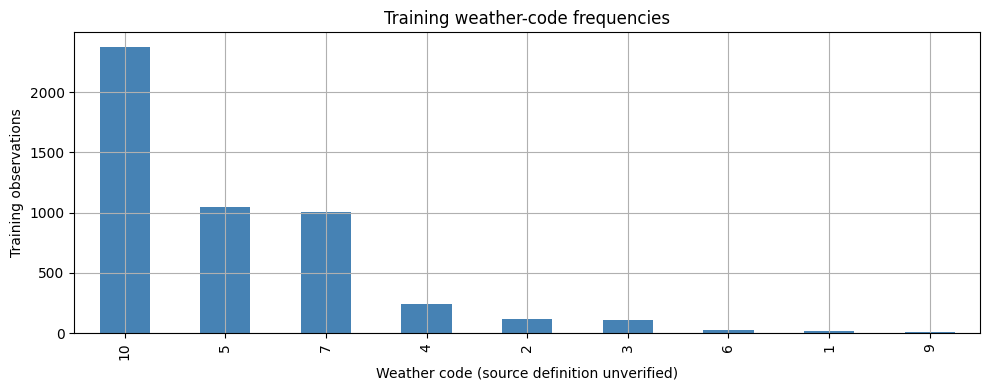

In [12]:
fig, ax = plt.subplots()
weather_counts.plot.bar(ax=ax, color="steelblue")
ax.set(xlabel="Weather code (source definition unverified)", ylabel="Training observations",
       title="Training weather-code frequencies")
plt.tight_layout()
plt.show()

## 4. Data Quality: Investigate, Do Not Repair
### 4.1 Missing values, marker tokens, and infinite values
Missing does not always mean `NaN`. Blank strings, `?`, `N/A`, or `-999` may be sentinels, but require source confirmation. Zero output is not automatically missing: it may reflect nighttime operation.

The second read below is a **text-only audit of the same training CSV**. It retains literal tokens for inspection, including ones pandas normally parses as missing. The numeric `-999` check also catches forms such as `-999.0`. These checks flag candidates; no values are replaced.

In [13]:
missing_report = pd.DataFrame({
    "missing_count": train_data.isna().sum(),
    "missing_percent": 100 * train_data.isna().mean(),
})
display(missing_report.sort_values("missing_count", ascending=False))

,missing_count,missing_percent
day,0,0.0
cosine_of_day,0,0.0
hour,0,0.0
cosine_of_hour,0,0.0
air_temperature,0,0.0
dewpoint,0,0.0
wind_speed,0,0.0
air_pressure,0,0.0
weather_condition,0,0.0
solar_radiation,0,0.0


#### Inspect possible missing-value markers

In [14]:
text_audit = pd.read_csv(TRAIN_PATH, dtype=str, keep_default_na=False)
marker_tokens = {"", "?", "n/a", "na", "nan", "null", "none", "-999"}
marker_counts = text_audit.apply(
    lambda column: column.str.strip().str.lower().isin(marker_tokens).sum()
)
numeric_columns = train_data.select_dtypes(include="number").columns.tolist()

marker_report = pd.DataFrame({
    "literal_marker_count": marker_counts,
    "numeric_minus_999_count": train_data.eq(-999).sum(),
    "infinite_count": np.isinf(train_data[numeric_columns]).sum(),
})
display(marker_report)
del text_audit

,literal_marker_count,numeric_minus_999_count,infinite_count
day,0,0,0
cosine_of_day,0,0,0
hour,0,0,0
cosine_of_hour,0,0,0
air_temperature,0,0,0
dewpoint,0,0,0
wind_speed,0,0,0
air_pressure,0,0,0
weather_condition,0,0,0
solar_radiation,0,0,0


### 4.2 Duplicate records and interval keys
Distinguish exact duplicate rows from repeated `(day, hour)` keys and repeated measurement profiles. Identical nighttime measurements at different times can be legitimate. Repeated time keys require checking year, device, and source provenance before removal.

No duplicate records are deleted.

In [15]:
duplicate_rows = train_data.duplicated(keep=False)
duplicate_keys = train_data.duplicated(subset=["day", "hour"], keep=False)
measurement_columns = [
    c for c in train_data if c not in {"day", "hour", "cosine_of_day", "cosine_of_hour"}
]
duplicate_report = pd.Series({
    "exact_duplicate_excess_rows": int(train_data.duplicated().sum()),
    "rows_in_exact_duplicate_groups": int(duplicate_rows.sum()),
    "repeated_time_key_excess_rows": int(train_data.duplicated(["day", "hour"]).sum()),
    "rows_in_repeated_time_key_groups": int(duplicate_keys.sum()),
    "repeated_measurement_excess_rows": int(train_data.duplicated(measurement_columns).sum()),
}, name="count")
display(duplicate_report.to_frame())
display(train_data.loc[duplicate_rows | duplicate_keys].head(10))

,count
exact_duplicate_excess_rows,0
rows_in_exact_duplicate_groups,0
repeated_time_key_excess_rows,0
rows_in_repeated_time_key_groups,0
repeated_measurement_excess_rows,136


,day,cosine_of_day,hour,cosine_of_hour,air_temperature,dewpoint,wind_speed,air_pressure,weather_condition,solar_radiation,...,pv_1_power,pv_2_cosine_value_of_the_solar_incidence_angle,pv_2_power,pv_3_cosine_value_of_the_solar_incidence_angle,pv_3_power,pv_4_cosine_value_of_the_solar_incidence_angle,pv_4_power,pv_5_cosine_value_of_the_solar_incidence_angle,pv_5_power,total_pv_power


### 4.3 Temporal order and continuity
The source uses day-of-year and hour labels **1–24**, with no confirmed year or timezone. Use `(day - 1) × 24 + (hour - 1)` as a relative interval coordinate, **not** a timezone-aware timestamp. No calendar year is fabricated.

Adjacent differences of 1 indicate consecutive labeled hours under a single-year assumption. Larger differences indicate gaps; zero or negative differences indicate repeated or unordered labels. Gaps are recorded, not filled. Verify real timestamps and reporting conventions before constructing next-hour targets.

Lesson 2 already checked the day/hour ranges and chronological order. Here we inspect continuity rather than repeat those validation gates. `relative_hour` is a temporary plotting coordinate, not a new dataset feature.

In [16]:
relative_hour = (train_data["day"] - 1) * 24 + train_data["hour"] - 1
hour_step = relative_hour.diff()
break_mask = hour_step.notna() & hour_step.ne(1)
time_breaks = train_data.loc[break_mask, ["day", "hour"]].copy()
time_breaks.insert(0, "previous_day", train_data["day"].shift(1).loc[break_mask])
time_breaks.insert(1, "previous_hour", train_data["hour"].shift(1).loc[break_mask])
time_breaks["elapsed_labeled_hours"] = hour_step.loc[break_mask]

print("Chronologically ordered:", relative_hour.is_monotonic_increasing)
print("Unique time keys:", relative_hour.is_unique)
print("Nonconsecutive adjacent pairs:", len(time_breaks))
display(time_breaks)

Chronologically ordered: True
Unique time keys: True
Nonconsecutive adjacent pairs: 0


,previous_day,previous_hour,day,hour,elapsed_labeled_hours


### 4.4 Domain checks and suspicious measurements
Flag negative radiation, wind speed, and output for review; do not assume every negative reading is a data-entry error. Sensor conventions, offsets, and system behavior matter. Cosines should lie within [-1, 1], allowing a small rounding tolerance.

Check whether total output agrees with the five component outputs. Agreement supports an arithmetic relationship, not proof of independent sensors or correct physical units. A disagreement needs investigation, not automatic replacement.

No hard upper bound on output or weather measurements is invented. In particular, confirm the definition and unit of `dewpoint` before comparing it with air temperature or relabeling it.

In [17]:
# Column groups reused in the EDA checks and plots below.
power_columns = [f"pv_{i}_power" for i in range(1, 6)]
cosine_columns = [column for column in train_data if "cosine" in column]

domain_flags = pd.DataFrame(index=train_data.index)
for column in ["solar_radiation", "wind_speed", "total_pv_power"] + power_columns:
    if column in train_data:
        domain_flags[f"negative_{column}"] = train_data[column].lt(0)
for column in cosine_columns:
    domain_flags[f"outside_cosine_range_{column}"] = train_data[column].abs().gt(1 + 1e-6)

if set(power_columns).issubset(train_data.columns):
    component_sum = train_data[power_columns].sum(axis=1, min_count=len(power_columns))
    sum_checkable = np.isfinite(component_sum) & np.isfinite(train_data["total_pv_power"])
    domain_flags["component_sum_mismatch"] = sum_checkable & ~np.isclose(
        component_sum, train_data["total_pv_power"], rtol=1e-6, atol=1e-6
    )
    print("Rows eligible for component-sum check:", int(sum_checkable.sum()))
    print("Rows not checked:", int((~sum_checkable).sum()))

domain_report = domain_flags.sum().rename("flagged_count").to_frame()
display(domain_report)
display(train_data.loc[domain_flags.any(axis=1)].head(10))

Rows eligible for component-sum check: 4956
Rows not checked: 0


,flagged_count
negative_solar_radiation,0
negative_wind_speed,0
negative_total_pv_power,0
negative_pv_1_power,0
negative_pv_2_power,0
negative_pv_3_power,0
negative_pv_4_power,0
negative_pv_5_power,0
outside_cosine_range_cosine_of_day,0
outside_cosine_range_cosine_of_hour,0


,day,cosine_of_day,hour,cosine_of_hour,air_temperature,dewpoint,wind_speed,air_pressure,weather_condition,solar_radiation,...,pv_1_power,pv_2_cosine_value_of_the_solar_incidence_angle,pv_2_power,pv_3_cosine_value_of_the_solar_incidence_angle,pv_3_power,pv_4_cosine_value_of_the_solar_incidence_angle,pv_4_power,pv_5_cosine_value_of_the_solar_incidence_angle,pv_5_power,total_pv_power


## 5. Descriptive Statistics and Distributions
### 5.1 Numeric summaries
Use `describe()` to inspect counts, center, spread, and range. Day/hour and weather codes have numerical storage but their means are not the primary interpretation.

For numerical calculations and plots only, use a separate view with non-finite values represented as missing. This **does not clean or overwrite** `train_data`; counts above document excluded non-finite readings. Pandas summaries omit missing values. Always inspect available counts.

In [18]:
numeric_view = train_data[numeric_columns].where(np.isfinite(train_data[numeric_columns]))
descriptive_statistics = numeric_view.describe().T
descriptive_statistics["skewness"] = numeric_view.skew()
display(descriptive_statistics)

,count,mean,std,min,25%,50%,75%,max,skewness
day,4956.0,103.750605,59.617780,1.000000,52.000000,104.000000,155.000000,207.000000,0.000061
cosine_of_day,4956.0,-0.117576,0.733213,-0.999963,-0.890028,-0.217723,0.625411,0.999852,0.203269
hour,4956.0,12.485472,6.922870,1.000000,6.000000,12.000000,18.000000,24.000000,0.003155
cosine_of_hour,4956.0,0.000202,0.707165,-1.000000,-0.707100,0.000000,0.707100,1.000000,-0.000285
air_temperature,4956.0,12.004439,9.998808,-14.000000,3.000000,12.000000,20.000000,36.000000,0.025939
dewpoint,4956.0,55.790759,21.600772,7.000000,38.000000,55.000000,74.000000,94.000000,-0.013375
wind_speed,4956.0,13.771388,8.582055,0.000000,7.000000,11.000000,19.000000,52.000000,0.901582
air_pressure,4956.0,897.272115,4.836563,879.000000,894.100000,897.600000,900.200000,910.000000,-0.180082
weather_condition,4956.0,7.646086,2.501311,1.000000,5.000000,7.000000,10.000000,10.000000,-0.478361
solar_radiation,4956.0,203.461784,285.060510,0.000000,0.000000,0.000000,384.250000,996.000000,1.199140


#### Plot numerical distributions

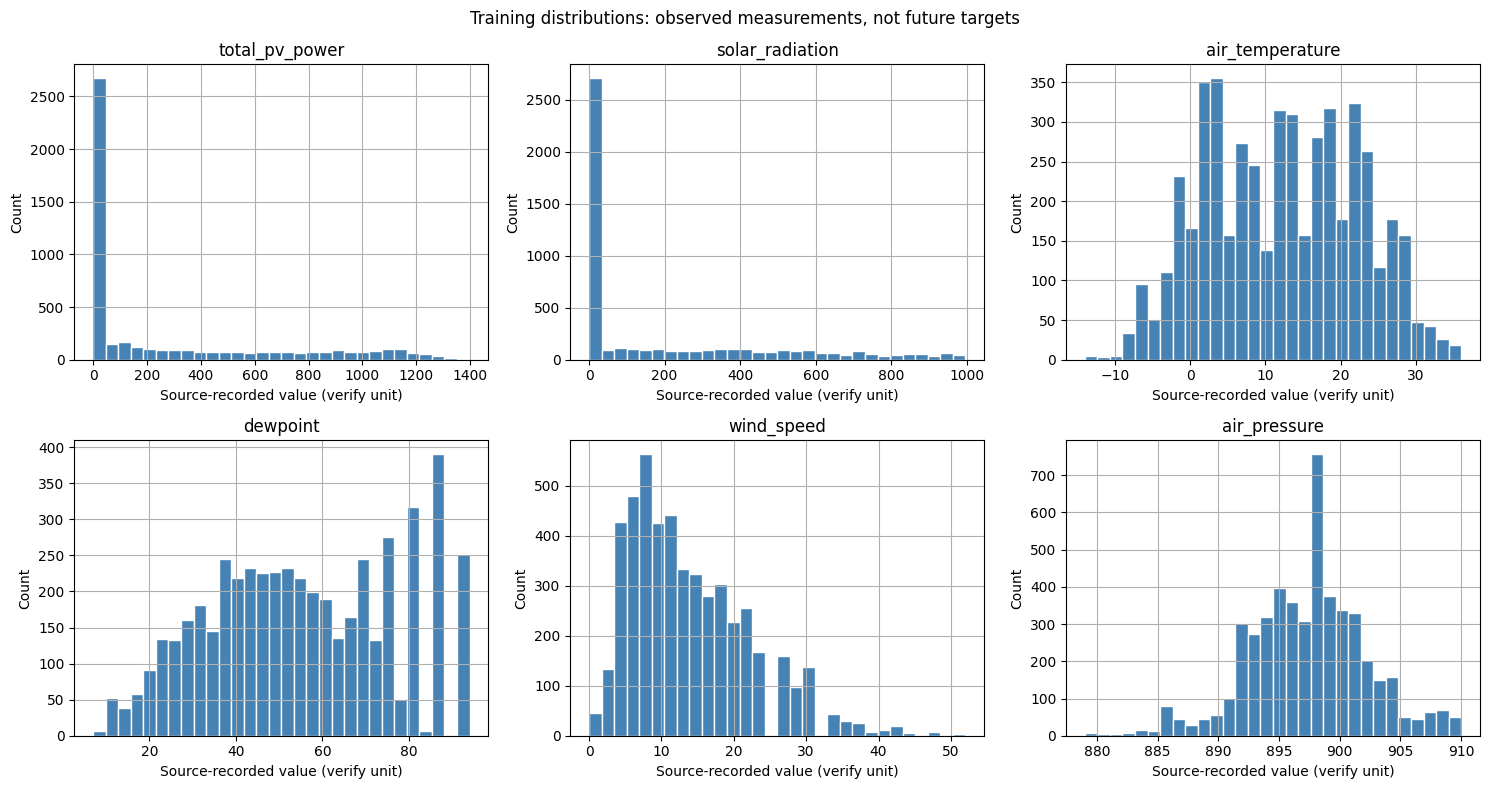

In [19]:
plot_columns = [
    "total_pv_power", "solar_radiation", "air_temperature",
    "dewpoint", "wind_speed", "air_pressure",
]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for column, ax in zip(plot_columns, axes.flat):
    ax.hist(numeric_view[column].dropna(), bins=30, color="steelblue", edgecolor="white")
    ax.set(title=column, xlabel="Source-recorded value (verify unit)", ylabel="Count")
fig.suptitle("Training distributions: observed measurements, not future targets")
plt.tight_layout()
plt.show()

### 5.2 Observed output and the future target distinction
A mass at zero, skewness, or multiple modes may reflect operating regimes rather than bad records. Inspect the all-observation distribution alongside positive output; the latter is a descriptive subset, **not** a new training set or a confirmed daylight filter.

A future target distribution will differ if gaps, boundaries, or missing targets exclude observations. Therefore, class balance remains **not yet defined**. Later, define any data-driven class boundaries from training targets only and freeze them before applying them elsewhere. Accuracy alone may mislead when classes are imbalanced.

In [20]:
observed_output = numeric_view["total_pv_power"]
output_summary = pd.Series({
    "finite_observations": observed_output.count(),
    "zero_output_count": observed_output.eq(0).sum(),
    "positive_output_count": observed_output.gt(0).sum(),
    "negative_output_count": observed_output.lt(0).sum(),
    "zero_percent_of_finite": 100 * observed_output.eq(0).sum() / max(observed_output.count(), 1),
}, name="value")
display(output_summary.to_frame())

,value
finite_observations,4956.000000
zero_output_count,2667.000000
positive_output_count,2289.000000
negative_output_count,0.000000
zero_percent_of_finite,53.813559


#### Plot observed output

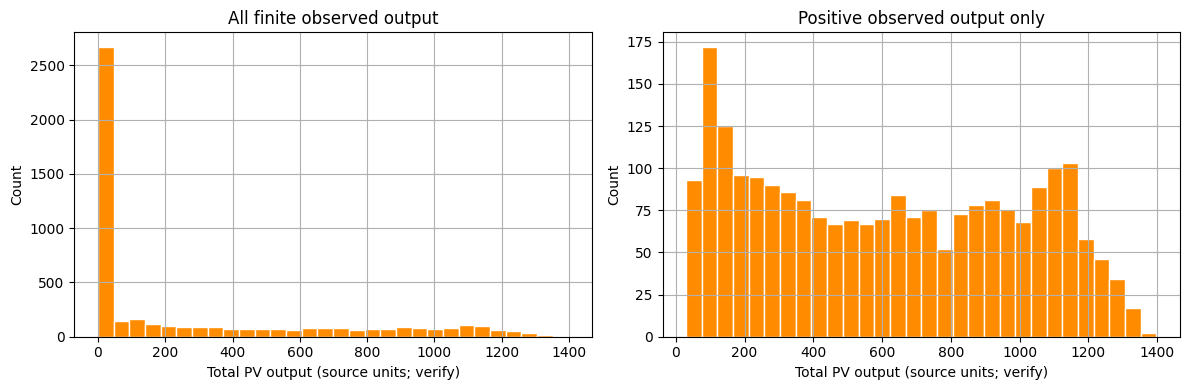

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, values, title in [
    (axes[0], observed_output.dropna(), "All finite observed output"),
    (axes[1], observed_output[observed_output > 0], "Positive observed output only"),
]:
    ax.hist(values, bins=30, color="darkorange", edgecolor="white")
    ax.set(title=title, xlabel="Total PV output (source units; verify)", ylabel="Count")
plt.tight_layout()
plt.show()

## 6. Relationships and Time-Based Patterns
### 6.1 Scatter plots and correlation
These are **same-interval associations**, not next-hour predictive performance. Correlation is not causation. Shared daily cycles, weather regimes, derived columns, and component-total arithmetic can produce strong correlations.

Exclude the weather category code and raw time keys from the Pearson matrix rather than implying meaningful numerical distances between categories. Correlations use pairwise complete finite observations. Inspect observation counts; no correlation threshold is used to select or remove features.

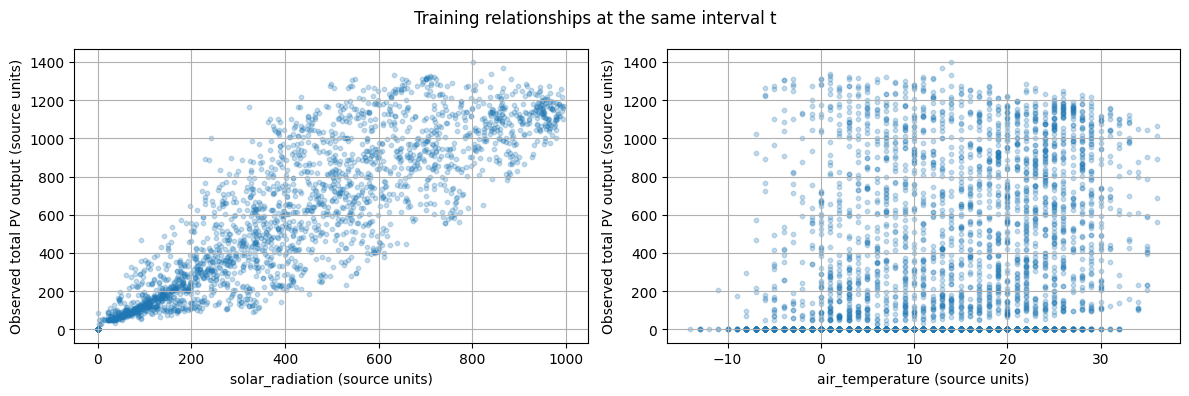

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column in zip(axes, ["solar_radiation", "air_temperature"]):
    ax.scatter(numeric_view[column], observed_output, s=10, alpha=0.25)
    ax.set(xlabel=f"{column} (source units)", ylabel="Observed total PV output (source units)")
fig.suptitle("Training relationships at the same interval t")
plt.tight_layout()
plt.show()

#### Calculate correlations

In [23]:
relationship_columns = plot_columns + [c for c in power_columns if c in numeric_view]
relationship_data = numeric_view[relationship_columns]
correlation = relationship_data.corr(min_periods=3)
available = relationship_data.notna().astype(int)
pair_counts = available.T @ available
display(correlation.round(3))
print("Minimum pairwise available count:", int(pair_counts.to_numpy().min()))

,total_pv_power,solar_radiation,air_temperature,dewpoint,wind_speed,air_pressure,pv_1_power,pv_2_power,pv_3_power,pv_4_power,pv_5_power
total_pv_power,1.000,0.939,0.306,-0.420,0.155,0.070,0.974,0.978,0.992,0.998,0.990
solar_radiation,0.939,1.000,0.436,-0.499,0.181,0.006,0.951,0.874,0.903,0.937,0.965
air_temperature,0.306,0.436,1.000,-0.748,0.188,-0.250,0.339,0.236,0.266,0.307,0.360
dewpoint,-0.420,-0.499,-0.748,1.000,-0.194,0.097,-0.466,-0.353,-0.381,-0.413,-0.454
wind_speed,0.155,0.181,0.188,-0.194,1.000,-0.289,0.178,0.122,0.137,0.154,0.175
air_pressure,0.070,0.006,-0.250,0.097,-0.289,1.000,0.051,0.102,0.086,0.067,0.040
pv_1_power,0.974,0.951,0.339,-0.466,0.178,0.051,1.000,0.916,0.942,0.963,0.980
pv_2_power,0.978,0.874,0.236,-0.353,0.122,0.102,0.916,1.000,0.989,0.975,0.944
pv_3_power,0.992,0.903,0.266,-0.381,0.137,0.086,0.942,0.989,1.000,0.992,0.970
pv_4_power,0.998,0.937,0.307,-0.413,0.154,0.067,0.963,0.975,0.992,1.000,0.990


Minimum pairwise available count: 4956


#### Plot the correlation matrix

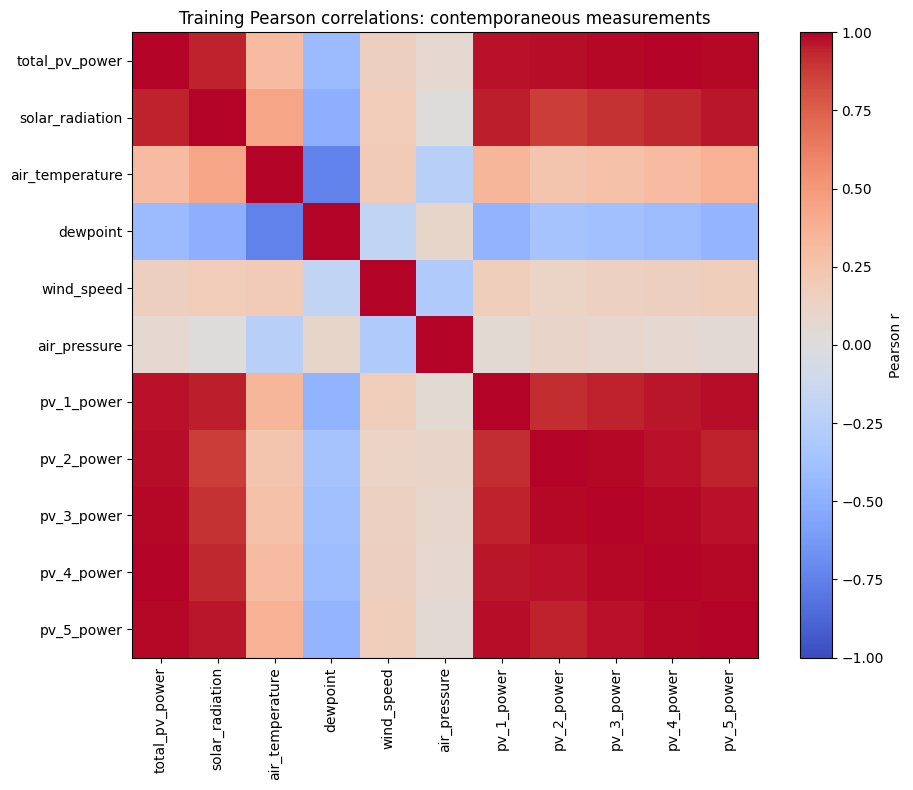

In [24]:
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(correlation)), correlation.columns, rotation=90)
ax.set_yticks(range(len(correlation)), correlation.index)
ax.set_title("Training Pearson correlations: contemporaneous measurements")
ax.grid(False)
fig.colorbar(image, ax=ax, label="Pearson r")
plt.tight_layout()
plt.show()

### 6.2 Grouped summaries
Summarize observed output by hour and weather code, with counts. These summaries are descriptive; differences can be confounded by time of day, season, and unequal group sizes.

Weather codes remain unnamed until their definitions are verified. Hour labels remain 1–24. This is not target encoding or a learned preprocessing transformation.

In [25]:
hourly_summary = observed_output.groupby(train_data["hour"]).agg(["count", "mean", "median"])
weather_summary = observed_output.groupby(train_data["weather_condition"]).agg(
    ["count", "mean", "median"]
)
display(hourly_summary)
display(weather_summary)

,count,mean,median
hour,,,
1,207,0.000000,0.0
2,207,0.000000,0.0
3,207,0.000000,0.0
4,207,0.000000,0.0
5,207,0.000000,0.0
6,207,0.000000,0.0
7,207,6.077295,0.0
8,207,143.753623,101.0
9,207,385.299517,326.0


,count,mean,median
weather_condition,,,
1,18,61.444444,0.0
2,113,207.292035,50.0
3,111,106.180180,0.0
4,238,156.915966,0.0
5,1049,267.696854,112.0
6,29,400.655172,136.0
7,1007,398.078451,193.0
9,13,808.000000,927.0
10,2378,261.979394,0.0


#### Plot output by hour

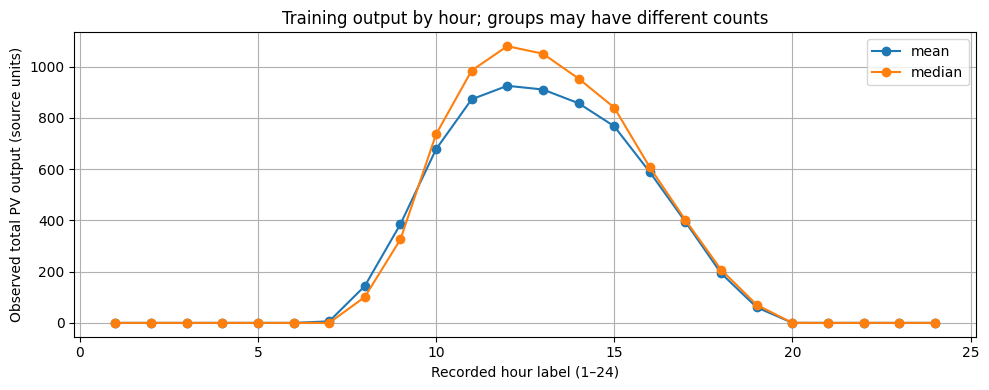

In [26]:
fig, ax = plt.subplots()
hourly_summary[["mean", "median"]].plot(ax=ax, marker="o")
ax.set(xlabel="Recorded hour label (1–24)", ylabel="Observed total PV output (source units)",
       title="Training output by hour; groups may have different counts")
plt.tight_layout()
plt.show()

### 6.3 Temporal coverage
Inspect the available training observations as points so lines do not imply continuity across gaps. The relative day coordinate is used only for plotting; it is not added to the dataset.

Daily summaries include counts: a mean from an incomplete day is not directly comparable with a full-day mean. Training coverage does not establish the seasonal composition of held-out data.

In [27]:
daily_summary = observed_output.groupby(train_data["day"]).agg(["count", "mean", "median"])
daily_summary["recorded_rows"] = train_data.groupby("day").size()
display(daily_summary.head())
print("Days with fewer than 24 recorded rows:", int(daily_summary["recorded_rows"].lt(24).sum()))

,count,mean,median,recorded_rows
day,,,,
1,24,212.458333,0.0,24
2,24,285.583333,0.0,24
3,24,156.875000,0.0,24
4,24,208.083333,0.0,24
5,24,59.625000,0.0,24


Days with fewer than 24 recorded rows: 1


#### Plot temporal coverage

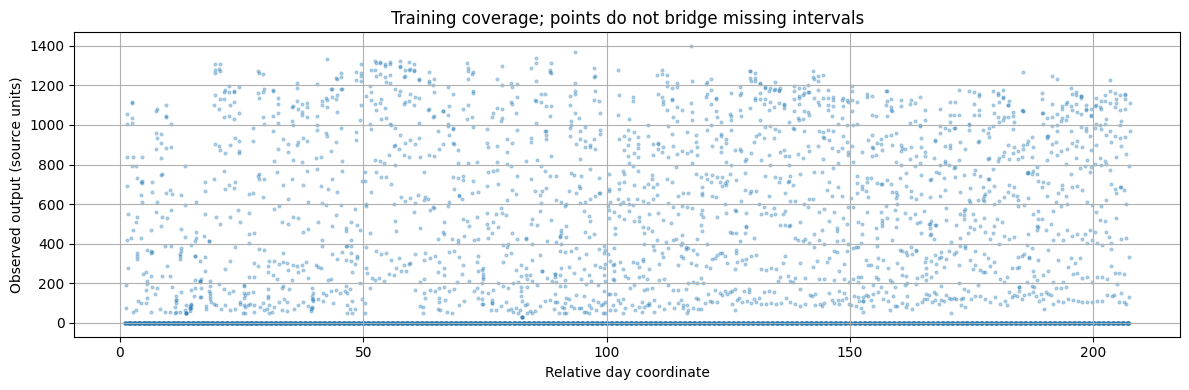

In [28]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.scatter(relative_hour / 24 + 1, observed_output, s=4, alpha=0.3)
ax.set(xlabel="Relative day coordinate", ylabel="Observed output (source units)",
       title="Training coverage; points do not bridge missing intervals")
plt.tight_layout()
plt.show()

## 7. Introductory Outlier Investigation
### 7.1 Box plots, IQR, and z-scores
A statistical outlier is **not automatically invalid**. It may be a rare valid event, unusual weather, a change in operation, or a sensor/data-entry issue.

- **IQR:** Q3 − Q1; exploratory fences are Q1 − 1.5 × IQR and Q3 + 1.5 × IQR.
- **Z-score:** (x − mean) / standard deviation; here use population standard deviation (`ddof=0`) and flag |z| > 3 as an introductory heuristic.
- Fit these summaries on training observations only. Constant columns have undefined z-scores; no flag is assigned by that method.
- Neither method assumes a physically justified upper bound. Skewed, zero-heavy PV output and mixed operating regimes can make global rules misleading. A z-score threshold is not a calibrated probability for this non-normal time series.

No observations are removed, clipped, replaced, or relabeled.

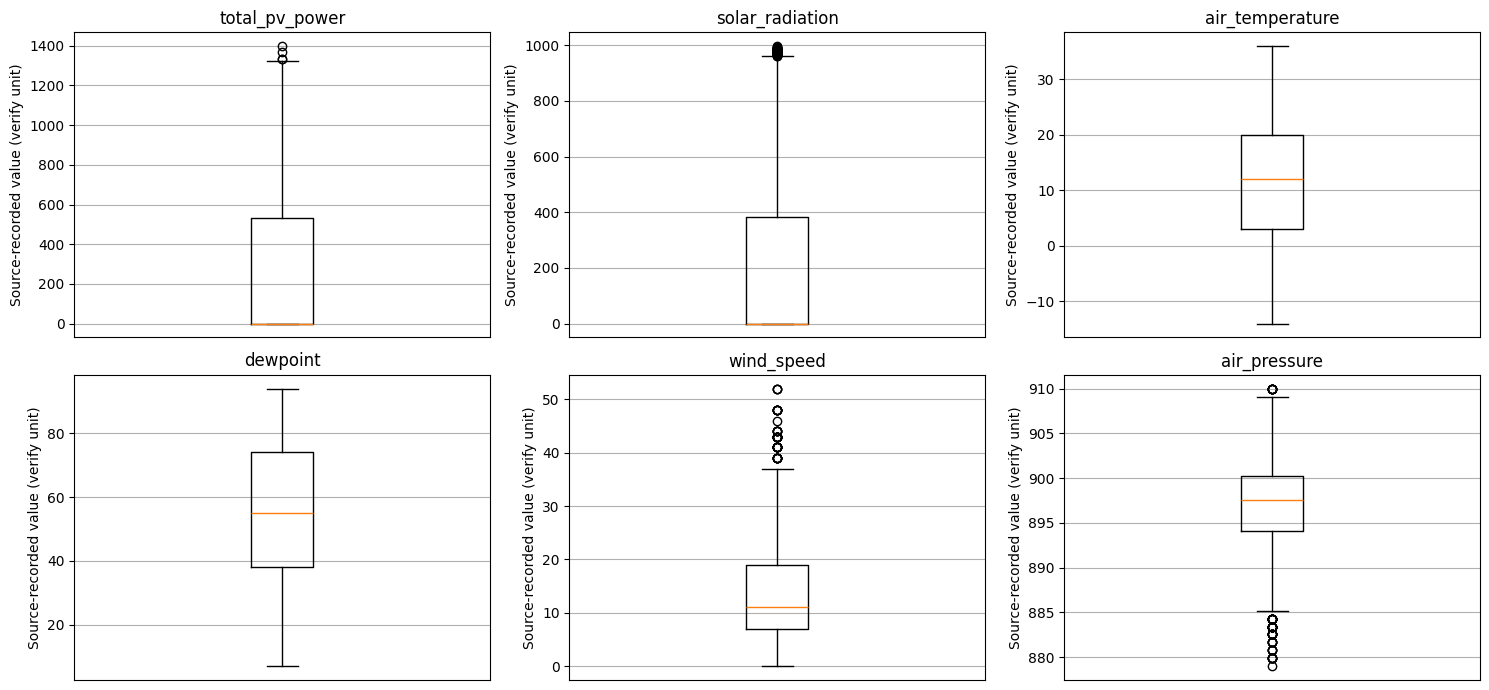

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for column, ax in zip(plot_columns, axes.flat):
    ax.boxplot(numeric_view[column].dropna(), vert=True)
    ax.set(title=column, ylabel="Source-recorded value (verify unit)", xticks=[])
plt.tight_layout()
plt.show()

#### Calculate IQR fences

In [30]:
outlier_data = numeric_view[plot_columns]
q1 = outlier_data.quantile(0.25)
q3 = outlier_data.quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
iqr_flags = outlier_data.lt(lower_fence) | outlier_data.gt(upper_fence)

#### Calculate z-scores

In [31]:
standard_deviation = outlier_data.std(ddof=0)
z_scores = (outlier_data - outlier_data.mean()) / standard_deviation.replace(0, np.nan)
z_flags = z_scores.abs().gt(3)

#### Compare outlier counts

In [32]:
outlier_report = pd.DataFrame({
    "finite_count": outlier_data.count(),
    "q1": q1, "q3": q3, "iqr": iqr,
    "lower_fence": lower_fence, "upper_fence": upper_fence,
    "iqr_flag_count": iqr_flags.sum(),
    "z_score_flag_count": z_flags.sum(),
    "zero_iqr": iqr.eq(0),
    "z_score_unavailable": standard_deviation.isna() | standard_deviation.eq(0),
})
display(outlier_report)

,finite_count,q1,q3,iqr,lower_fence,upper_fence,iqr_flag_count,z_score_flag_count,zero_iqr,z_score_unavailable
total_pv_power,4956,0.0,533.00,533.00,-799.500,1332.500,4,0,False,False
solar_radiation,4956,0.0,384.25,384.25,-576.375,960.625,50,0,False,False
air_temperature,4956,3.0,20.00,17.00,-22.500,45.500,0,0,False,False
dewpoint,4956,38.0,74.00,36.00,-16.000,128.000,0,0,False,False
wind_speed,4956,7.0,19.00,12.00,-11.000,37.000,55,47,False,False
air_pressure,4956,894.1,900.20,6.10,884.950,909.350,61,24,False,False


### 7.2 Inspect flagged observations in context
Look at time labels, output, radiation, and weather together. The table below is a review queue, not a deletion list; only its first ten rows are displayed. Inspect additional rows of `review_queue` as needed.

For each candidate ask: Is the source reliable? Are the units known? Is the value physically plausible? Is it consistent with neighboring hours and component measurements? Is it relevant to the intended prediction problem?

In [33]:
review_mask = iqr_flags.any(axis=1) | z_flags.any(axis=1) | domain_flags.any(axis=1)
review_queue = train_data.loc[
    review_mask, ["day", "hour", "weather_condition"] + plot_columns
].copy()
print("Observations requiring contextual review:", len(review_queue))
display(review_queue.head(10))

Observations requiring contextual review: 165


,day,hour,weather_condition,total_pv_power,solar_radiation,air_temperature,dewpoint,wind_speed,air_pressure
279,12,16,4,379,209.0,18,40,43,896.7
291,13,4,4,0,0.0,13,38,44,889.6
295,13,8,4,0,0.0,12,54,43,887.0
296,13,9,4,67,37.0,11,62,44,886.1
297,13,10,4,595,249.0,14,51,43,886.1
298,13,11,4,791,401.0,16,42,48,885.2
299,13,12,4,435,263.0,15,42,43,884.3
381,16,22,2,0,0.0,3,10,0,884.3
382,16,23,4,0,0.0,4,93,11,884.3
383,16,24,5,0,0.0,4,93,20,883.4


## 8. Leakage Signals and Prediction-Time Availability
High correlation is neither necessary nor sufficient evidence of leakage. Check **when and how** each column becomes available.

| Column or situation | Risk / interpretation | Later action |
|---|---|---|
| `total_pv_power` and component powers at t | Potential historical inputs for predicting t+1, only if reported by the prediction origin | Confirm reporting latency |
| Component powers used to predict total at the same t | Can reconstruct the outcome rather than forecast it | Keep the next-hour task explicit |
| Observed radiation/weather at t+1 | Future information unavailable at origin t | Do not use future observations as inputs |
| Cosines and day/hour labels | Temporal/geometric information, not automatically leakage | Verify calculation and calendar conventions |
| Future target columns or post-event status | May reveal the outcome | Audit provenance, not just names |
| Repeated records/groups across partitions | May undermine independent evaluation | Preserve Lesson 2 split; verify lineage in split auditing, not test-statistic-driven EDA |
| Randomly shuffled time records | May mix future and past | Preserve chronological order |

Review these risks using source documentation and measurement timing. A column-name search alone cannot establish whether leakage exists.

## 9. EDA Summary
These findings describe the **4,956-row, 21-column training partition** supplied by Lesson 2. Revisit this summary if the input data or split changes.

- **Data quality and time:** No parsed missing values, exact duplicate records, or repeated time keys were found. Training observations are chronologically ordered, with one-hour steps throughout. These checks do not establish that every source value is correct.
- **Observed output:** 2,667 observations (53.8%) have zero total PV output. Investigate operating conditions rather than treating zeros as missing values.
- **Relationships:** Total output matches the sum of the five component outputs within the checked tolerance. This same-interval relationship is not evidence of next-hour forecasting performance; input availability must be verified.
- **Potential outliers:** Across the six inspected numerical columns, IQR flags 165 rows and z-scores flag 71. These methods need not agree, and a flag is not a reason for automatic deletion. The implemented domain checks flag no rows.